## Partie 4 — Transférer à la maintenance (AI4I 2020)

### Objectif
Réutiliser les méthodes retenues sur Credit Card (Isolation Forest + meilleur modèle supervisé)
sur un jeu de **maintenance prédictive**, avec le **même protocole d’évaluation**,
mais un seuil recalibré sous la contrainte **précision ≥ 90 %**.

Les observations AI4I sont **synthétiques** : les conclusions restent pédagogiques.

### 4.a — Chargement et préparation de la cible
- Cible : **`Machine failure`** (1 = panne, 0 = normal)
- On retire les identifiants : `UDI`, `Product ID`
- On retire aussi `TWF`, `HDF`, `PWF`, `OSF`, `RNF`  
  (types de panne qui **fuiteraient** directement vers la cible)

Les labels / colonnes de panne ne doivent pas servir d’entrées prédictives.

In [1]:
from utils_ai4i import load_ai4i, check_ai4i

X_ai4i, y_ai4i, df_ai4i = load_ai4i("../data/ai4i2020.csv")
check_ai4i(X_ai4i, y_ai4i, df_ai4i)

=== AI4I 2020 ===
Shape X : (10000, 6)
Colonnes X : ['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']
Valeurs manquantes :
 Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
dtype: int64
Nb pannes (1) : 339 (3.39 %)
Nb normaux (0) : 9661

Colonnes retirées (fuite / id) : ['UDI', 'Product ID', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']
Aperçu :
  Type  Air temperature [K]  Process temperature [K]  Rotational speed [rpm]  \
0    M                298.1                    308.6                    1551   
1    L                298.2                    308.7                    1408   
2    L                298.1                    308.5                    1498   
3    L                298.2                    308.6                    1433   
4    L                298.2                    308.7                 

### 4.b — Fréquence des pannes, split et prétraitement

- On examine la **fréquence des pannes** (jeu déséquilibré ~3 %).
- Split stratifié reproductible : **60 % train / 20 % val / 20 % test**
  (même protocole que Credit Card).
- Prétraitement :
  - `Type` → **OneHotEncoder**
  - variables numériques → **StandardScaler**
- **Fit uniquement sur le train**, puis application à val/test  
  (pas de fuite de données).
- Les observations AI4I sont **synthétiques**.

In [3]:
import importlib
import utils_ai4i
importlib.reload(utils_ai4i)

from utils_ai4i import split_ai4i, preprocess_ai4i

X_train, X_val, X_test, y_train, y_val, y_test = split_ai4i(X_ai4i, y_ai4i)

for name, y in [("Train", y_train), ("Val", y_val), ("Test", y_test)]:
    print(f"{name:5s} : n={len(y):5d} | pannes={int(y.sum()):3d} ({100 * y.mean():.2f} %)")

X_train_p, X_val_p, X_test_p, preproc, cat_cols, num_cols = preprocess_ai4i(
    X_train, X_val, X_test
)

print("\nCatégorielles :", cat_cols)
print("Numériques    :", num_cols)
print("Shapes :", X_train_p.shape, X_val_p.shape, X_test_p.shape)

Train : n= 6000 | pannes=203 (3.38 %)
Val   : n= 2000 | pannes= 68 (3.40 %)
Test  : n= 2000 | pannes= 68 (3.40 %)

Catégorielles : ['Type']
Numériques    : ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']
Shapes : (6000, 8) (2000, 8) (2000, 8)


### 4.c — Réutiliser IF et le meilleur modèle supervisé (Credit Card)

Conformément au sujet :
- on reprend **Isolation Forest** et la **Régression Logistique** retenus sur Credit Card ;
- on **conserve les hyperparamètres** ;
- on **réajuste** les modèles (et le prétraitement) sur AI4I ;
- on **ne réutilise pas** la même valeur numérique de seuil qu’en fraudes.

Modèles repris :
- **IF** : `n_estimators=100`, `contamination="auto"`, `random_state=42`
- **LR** : `C=1.0`, sans correction du déséquilibre, `max_iter=1000`, `random_state=42`

In [5]:
import time
import numpy as np
from sklearn.ensemble import IsolationForest
from sklearn.linear_model import LogisticRegression

# --- Isolation Forest (hyperparams Credit Card) ---
t0 = time.time()
if_ai4i = IsolationForest(
    n_estimators=100, contamination="auto", random_state=42, n_jobs=-1
)
if_ai4i.fit(X_train_p)
t_if = time.time() - t0

# scores : plus haut = plus suspect
scores_if_val = -if_ai4i.score_samples(X_val_p)
scores_if_test = -if_ai4i.score_samples(X_test_p)

# --- Régression logistique (meilleur modèle Credit Card) ---
t0 = time.time()
lr_ai4i = LogisticRegression(C=1.0, max_iter=1000, random_state=42)
lr_ai4i.fit(X_train_p, y_train)
t_lr = time.time() - t0

scores_lr_val = lr_ai4i.predict_proba(X_val_p)[:, 1]
scores_lr_test = lr_ai4i.predict_proba(X_test_p)[:, 1]

print(f"Temps IF : {t_if:.3f}s | Temps LR : {t_lr:.3f}s")
print("Scores prêts sur validation et test.")

Temps IF : 0.117s | Temps LR : 0.009s
Scores prêts sur validation et test.


### Résultats 4.c — entraînement et scores

Nous avons réentraîné sur AI4I les deux modèles retenus sur Credit Card,
**en conservant leurs hyperparamètres** :

| Modèle | Hyperparamètres repris | Type |
|--------|------------------------|------|
| Isolation Forest | `n_estimators=100`, `contamination="auto"`, `random_state=42` | non supervisé |
| Régression logistique | `C=1.0`, sans correction du déséquilibre | supervisé |

#### Ce qui a été obtenu
- Les modèles sont bien ajustés sur `X_train_p`.
- Des **scores continus** ont été calculés sur la validation et le test :
  - IF : `scores_if_val`, `scores_if_test`
  - LR : `scores_lr_val`, `scores_lr_test`
- Un score élevé = observation plus suspecte (panne probable).

#### Lecture à ce stade
À ce stade, on **ne décide pas encore** “panne / pas panne” :
aucun seuil n’a été appliqué.  
Donc on ne peut pas encore dire si le transfert est “bon” au sens métier
(précision ≥ 90 %, rappel, interventions inutiles, etc.).

Ce que l’on peut déjà confirmer :
- le protocole de transfert (hyperparams figés, modèles réajustés) est respecté ;
- les scores sont disponibles pour la calibration du seuil en **4.d**.

Le choix du seuil et l’évaluation quantitative se font ensuite sur la validation,
puis le test, avec la contrainte **précision ≥ 90 %**.

### 4.d — Choix du seuil (précision ≥ 90 %) puis évaluation test

Sur la **validation**, pour chaque modèle :
- maximiser le **rappel** sous contrainte **précision ≥ 90 %** ;
- au moins une alerte ;
- si impossible → signaler **« objectif non atteint »** et garder le meilleur compromis (règle de `trouver_meilleur_seuil`).

Ensuite : **figer** modèle + seuil, évaluer le **test**  
(précision / rappel / F1 / balanced accuracy + FP = interventions inutiles, FN = pannes manquées).

On réutilise les fonctions de `utils_credit` **sans les modifier**.

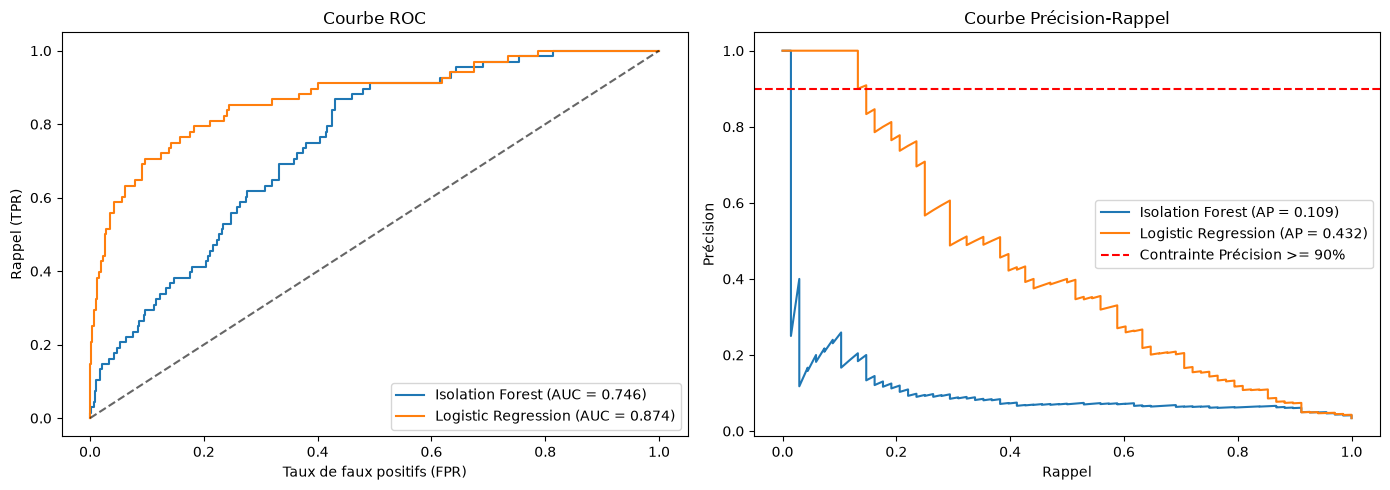

=== Validation (choix du seuil) ===


,Méthode,Seuil,TP (Fraudes détectées),FP (Fausses alertes),FN (Fraudes manquées),TN (Normales correctes),Précision,Rappel,F1-score,Balanced Accuracy,AP,AUC-ROC,Contrainte (>=80%)
0,Isolation Forest,0.674657,1,0,67,1932,1.0000,0.0147,0.0290,0.5074,0.1093,0.7460,Atteint
1,Logistic Regression,0.681069,10,1,58,1931,0.9091,0.1471,0.2532,0.5733,0.4321,0.8737,Atteint


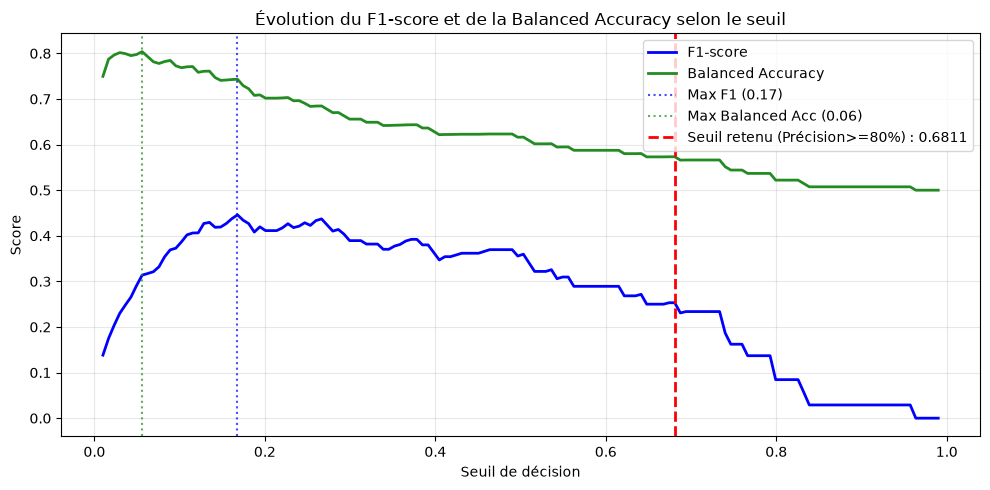

=== Test (évaluation finale) ===


,Méthode,Seuil,TP (Fraudes détectées),FP (Fausses alertes),FN (Fraudes manquées),TN (Normales correctes),Précision,Rappel,F1-score,Balanced Accuracy,Seuil (figé val)
0,Isolation Forest,0.674657,0,1,68,1931,0.00,0.0000,0.0000,0.4997,0.674657
1,Logistic Regression,0.681069,3,1,65,1931,0.75,0.0441,0.0833,0.5218,0.681069



FP = interventions inutiles | FN = pannes manquées


In [8]:
import importlib
import utils_credit
importlib.reload(utils_credit)

from utils_credit import (
    trouver_meilleur_seuil,
    evaluer_seuil,
    tracer_courbes_roc_pr,
    tracer_f1_balanced_acc,
)
import pandas as pd

# 1) Courbes ROC / PR sur la validation (contrainte 90 %)
tracer_courbes_roc_pr(
    y_val,
    {"Isolation Forest": scores_if_val, "Logistic Regression": scores_lr_val},
    min_precision=0.90,
)

# 2) Seuil optimal sur VALIDATION
res_if_val = trouver_meilleur_seuil(y_val, scores_if_val, min_precision=0.90)
res_lr_val = trouver_meilleur_seuil(y_val, scores_lr_val, min_precision=0.90)

df_val = pd.DataFrame([
    {"Méthode": "Isolation Forest", **res_if_val},
    {"Méthode": "Logistic Regression", **res_lr_val},
])
print("=== Validation (choix du seuil) ===")
display(df_val)

seuil_if = res_if_val["Seuil"]
seuil_lr = res_lr_val["Seuil"]

tracer_f1_balanced_acc(y_val, scores_lr_val, seuil_retenu=seuil_lr)

# 3) Test avec seuils figés
res_if_test = evaluer_seuil(y_test, scores_if_test, seuil=seuil_if)
res_lr_test = evaluer_seuil(y_test, scores_lr_test, seuil=seuil_lr)

df_test = pd.DataFrame([
    {"Méthode": "Isolation Forest", **res_if_test, "Seuil (figé val)": seuil_if},
    {"Méthode": "Logistic Regression", **res_lr_test, "Seuil (figé val)": seuil_lr},
])
print("=== Test (évaluation finale) ===")
display(df_test)

print("\nFP = interventions inutiles | FN = pannes manquées")

### Résultats 4.d — seuil et test

#### Validation (contrainte précision ≥ 90 %)
| Méthode | Seuil | Précision | Rappel | TP | FP | FN | AP | AUC |
|---------|-------|-----------|--------|----|----|----|----|-----|
| Isolation Forest | ≈ 0.67 | 1.00 | 0.015 | 1 | 0 | 67 | 0.11 | 0.75 |
| Logistic Regression | ≈ 0.68 | 0.91 | 0.15 | 10 | 1 | 58 | 0.43 | 0.87 |

Les deux atteignent la contrainte sur la validation, mais avec un rappel faible
(peu d’alertes pour garder une haute précision).
**LR est meilleure** que IF (meilleur AP/AUC et meilleur rappel).

#### Test (seuils figés, non retouchés)
| Méthode | Précision | Rappel | TP | FP | FN |
|---------|-----------|--------|----|----|----|
| Isolation Forest | 0.00 | 0.00 | 0 | 1 | 68 |
| Logistic Regression | 0.75 | 0.044 | 3 | 1 | 65 |

- **FP** = interventions inutiles  
- **FN** = pannes manquées  
- Sur le test, LR ne garde plus la précision ≥ 90 % (0.75) : on le signale
  **sans modifier le seuil après coup**.

### 4.e — Pourquoi le gagnant fraudes peut perdre ici
- Autre problème (pannes ≠ fraudes), autres variables, taux de positifs différent (~3 %).
- Contrainte plus dure (90 % vs 80 %).
- On ne compare pas directement les AP Credit Card vs AI4I.

### 4.e — Pourquoi la méthode gagnante sur les fraudes peut ne pas être la meilleure sur les pannes

Le meilleur modèle sur Credit Card (Régression logistique, `C=1.0`) reste ici
meilleur qu’Isolation Forest, mais ses performances se dégradent fortement
sous la contrainte maintenance.

#### Ce qui change entre les deux problèmes
1. **Cible différente** : fraude bancaire ≠ panne machine.
2. **Variables différentes** : V1…V28 + Amount vs capteurs industriels (`Type`, températures, couple, etc.).
3. **Proportion de positifs différente** : ~0.17 % de fraudes vs ~3.4 % de pannes.
4. **Contrainte plus stricte** : précision ≥ **90 %** (maintenance) vs ≥ **80 %** (fraude).
5. **Coût métier différent** : chaque alerte maintenance entraîne une intervention coûteuse,
   donc on accepte moins de fausses alertes → moins de rappels.

#### Conséquence observée
Pour respecter précision ≥ 90 % sur la validation, le seuil devient très exigeant :
peu d’alertes, rappel faible, beaucoup de pannes manquées (FN).
Sur le test, la contrainte n’est plus toujours tenue : il faut le signaler
sans retoucher le seuil.

#### Limite de comparaison
On ne compare **pas** directement les AP (ou AUC) de Credit Card et AI4I
comme s’ils avaient la même difficulté ou la même proportion de positifs.
Un bon score sur un jeu n’implique pas un bon score sur l’autre.

#### Conclusion Partie 4
Le transfert de protocole est valide (mêmes modèles/hyperparams, seuil recalibré),
mais le succès métier ne se transfère pas automatiquement.
Sur AI4I, LR > IF, pourtant le système reste peu sensible sous la contrainte 90 %.